# LLM-as-Judge — Meta-Metric Evaluation (10% Subsample)

**Goal:** Use Llama 3.3 70B as an independent judge to score the consistency of k=5 responses for a 10% subsample (~30 question-model pairs)  
**Input:** `rq1_responses.csv` (raw responses, T=0.7)  
**Output:** `llm_judge_scores.csv`  
**API calls:** ~30 judge calls (one per question-model pair, low cost)  

The judge reads all 5 responses for a question-model pair and scores consistency 1–5 with reasoning.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Cell 1 — Setup + Sample Selection

In [ ]:
!pip install -q groq

import pandas as pd
import numpy as np
import json, time, os, re
from groq import Groq

# ── Paths ─────────────────────────────────────────────────────────────────────
RESPONSES_PATH = "/content/drive/MyDrive/Thesis/rq1_responses.csv"
METRICS_PATH   = "/content/drive/MyDrive/Thesis/rq1_metrics_complete.csv"
JUDGE_OUT      = "/content/drive/MyDrive/Thesis/llm_judge_scores.csv"

GROQ_KEY = "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"
client   = Groq(api_key=GROQ_KEY)
JUDGE_MODEL = "llama-3.3-70b-versatile"  # separate model from experimental models

# ── Load data ─────────────────────────────────────────────────────────────────
MODELS = ["llama-4-scout", "llama-3.1-8b", "mistral-7b"]
df_resp    = pd.read_csv(RESPONSES_PATH)
df_resp    = df_resp[df_resp["model"].isin(MODELS)].copy()
df_metrics = pd.read_csv(METRICS_PATH)

print(f"Responses: {len(df_resp)}")
print(f"Metrics  : {len(df_metrics)} rows")

# ── Stratified 10% sample: ~2–3 questions per type × per model (~30 pairs) ───
# Sample proportionally from each Type × Model cell
np.random.seed(42)
Q_TYPES = ["FACTUAL", "PROCEDURAL", "ADVISORY", "HYPOTHETICAL"]

# Get unique Q_id per type
type_qids = {t: df_metrics[df_metrics["Type"] == t]["Q_id"].unique() for t in Q_TYPES}

# Sample ~2-3 Q_ids per type (total ~10 questions, ×3 models = 30 pairs)
N_PER_TYPE = 3  # adjust to get ~30 total
sampled_qids = []
for t in Q_TYPES:
    qids = type_qids[t]
    sampled = np.random.choice(qids, size=min(N_PER_TYPE, len(qids)), replace=False)
    sampled_qids.extend(sampled)

print(f"\nSampled {len(sampled_qids)} questions × {len(MODELS)} models = {len(sampled_qids)*len(MODELS)} judge calls")
print(f"Questions: {sampled_qids}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.7/143.7 kB 9.0 MB/s eta 0:00:00
Responses: 1500
Metrics  : 300 rows

Sampled 12 questions × 3 models = 36 judge calls
Questions: ['F09', 'F17', 'F01', 'P39', 'P36', 'P31', 'A66', 'A67', 'A55', 'H99', 'H77', 'H80']


## Cell 2 — Run LLM-as-Judge  (~5–10 min)

In [ ]:
JUDGE_PROMPT = """You are an expert evaluator assessing the **consistency** of multiple responses generated by an AI assistant to the same disaster advisory question.

You will be given:
- The original question
- 5 responses generated independently to that question

Your task is to assess how **consistent** these responses are with each other — i.e., whether they convey the same key information, advice, and meaning.

Score consistency on a scale of 1 to 5:
- 5: All responses are highly consistent — same key points, same recommendations, same meaning
- 4: Mostly consistent with minor variations in phrasing or detail level
- 3: Moderate consistency — some responses differ meaningfully in content or advice
- 2: Low consistency — responses often contradict or omit important information from each other
- 1: Very inconsistent — responses are substantially different in content or advice

**Question:** {question}

**Response 1:** {r1}

**Response 2:** {r2}

**Response 3:** {r3}

**Response 4:** {r4}

**Response 5:** {r5}

Respond ONLY with a JSON object in this exact format:
{{"score": <integer 1-5>, "reasoning": "<one sentence explaining the score>"}}"""

def judge_responses(question, responses, retries=3):
    """Call LLM judge and return (score, reasoning)."""
    prompt = JUDGE_PROMPT.format(
        question=question,
        r1=responses[0], r2=responses[1], r3=responses[2],
        r4=responses[3], r5=responses[4]
    )
    for attempt in range(retries):
        try:
            resp = client.chat.completions.create(
                model=JUDGE_MODEL,
                messages=[{"role": "user", "content": prompt}],
                temperature=0.0,
                max_tokens=256,
            )
            text = resp.choices[0].message.content.strip()
            # Extract JSON robustly
            match = re.search(r'\{.*\}', text, re.DOTALL)
            if match:
                result = json.loads(match.group())
                score = int(result["score"])
                reasoning = str(result["reasoning"])
                if 1 <= score <= 5:
                    return score, reasoning
        except Exception as e:
            print(f"  Attempt {attempt+1} failed: {e}")
            time.sleep(3)
    return None, "parsing_failed"

# ── Resume support ────────────────────────────────────────────────────────────
done = set()
if os.path.exists(JUDGE_OUT):
    existing = pd.read_csv(JUDGE_OUT)
    done = set(zip(existing["Q_id"], existing["model"]))
    print(f"Resuming — {len(done)} pairs already judged")

judge_records = []
total = len(sampled_qids) * len(MODELS)
count = 0

for qid in sampled_qids:
    for model_name in MODELS:
        if (qid, model_name) in done:
            count += 1
            continue

        # Get the 5 responses for this Q_id × model
        subset = df_resp[(df_resp["Q_id"] == qid) & (df_resp["model"] == model_name)]
        responses = subset["response"].dropna().tolist()
        question  = subset["Question"].iloc[0] if len(subset) > 0 else qid
        qtype     = subset["Type"].iloc[0] if len(subset) > 0 else "UNKNOWN"

        if len(responses) < 5:
            print(f"  WARNING: {qid} {model_name} has only {len(responses)} responses, skipping")
            continue

        score, reasoning = judge_responses(question, responses[:5])
        count += 1

        # Get automated metrics for this pair (for correlation later)
        row = df_metrics[(df_metrics["Q_id"] == qid) & (df_metrics["model"] == model_name)]
        sas_val = float(row["SAS"].iloc[0]) if len(row) > 0 else None
        cr_val  = float(row["CR"].iloc[0])  if len(row) > 0 else None

        judge_records.append({
            "Q_id":      qid,
            "Type":      qtype,
            "model":     model_name,
            "judge_score": score,
            "judge_reasoning": reasoning,
            "SAS":       sas_val,
            "CR":        cr_val,
        })
        print(f"  [{count}/{total}] {qid} | {model_name} → score={score} | {reasoning[:70]}...")
        time.sleep(1.5)

# ── Save ──────────────────────────────────────────────────────────────────────
if judge_records:
    judge_df = pd.DataFrame(judge_records)
    if os.path.exists(JUDGE_OUT) and done:
        existing = pd.read_csv(JUDGE_OUT)
        judge_df = pd.concat([existing, judge_df], ignore_index=True)
    judge_df.to_csv(JUDGE_OUT, index=False)
    print(f"\nSaved → {JUDGE_OUT}  ({len(judge_df)} rows)")
else:
    judge_df = pd.read_csv(JUDGE_OUT)
    print(f"All pairs already done. Loaded {len(judge_df)} rows.")

  [1/36] F09 | llama-4-scout → score=5 | All responses are highly consistent as they convey the same key inform...
  [2/36] F09 | llama-3.1-8b → score=2 | The responses often contradict or omit important information from each...
  [3/36] F09 | mistral-7b → score=5 | All responses are highly consistent as they convey the same key points...
  [4/36] F17 | llama-4-scout → score=5 | All responses are highly consistent in advising the user to check with...
  [5/36] F17 | llama-3.1-8b → score=4 | The responses are mostly consistent with minor variations in phrasing ...
  [6/36] F17 | mistral-7b → score=4 | The responses are mostly consistent with minor variations in phrasing ...
  [7/36] F01 | llama-4-scout → score=4 | The responses are mostly consistent with minor variations in phrasing ...
  [8/36] F01 | llama-3.1-8b → score=2 | The responses are low in consistency as they often omit important info...
  [9/36] F01 | mistral-7b → score=4 | The responses are mostly consistent with minor vari

## Cell 3 — Analysis: Judge Scores + Correlation with Automated Metrics

In [ ]:
from scipy import stats

judge_df = pd.read_csv(JUDGE_OUT)
print(f"Loaded {len(judge_df)} judged pairs")
print("\n── Judge score distribution ──")
print(judge_df["judge_score"].value_counts().sort_index().to_string())
print(f"\nMean judge score: {judge_df['judge_score'].mean():.3f} ± {judge_df['judge_score'].std():.3f}")

print("\n── Mean judge score by model ──")
print(judge_df.groupby("model")["judge_score"].agg(["mean","std"]).round(3).to_string())

print("\n── Mean judge score by question type ──")
print(judge_df.groupby("Type")["judge_score"].agg(["mean","std"]).round(3).to_string())

# ── Correlation: judge score vs automated metrics ─────────────────────────────
print("\n" + "=" * 55)
print("CORRELATION — Judge Score vs Automated Metrics")
print("=" * 55)
sub = judge_df.dropna(subset=["judge_score", "SAS", "CR"])

r_sas, p_sas = stats.spearmanr(sub["judge_score"], sub["SAS"])
r_cr,  p_cr  = stats.spearmanr(sub["judge_score"], sub["CR"])

print(f"Spearman r (Judge vs SAS): r={r_sas:.4f}, p={p_sas:.4f}")
print(f"Spearman r (Judge vs CR):  r={r_cr:.4f},  p={p_cr:.4f}")

interp_sas = "strong" if abs(r_sas) > 0.6 else ("moderate" if abs(r_sas) > 0.4 else "weak")
interp_cr  = "strong" if abs(r_cr)  > 0.6 else ("moderate" if abs(r_cr)  > 0.4 else "weak")
print(f"\n→ LLM judge shows {interp_sas} agreement with SAS ({r_sas:+.3f})")
print(f"→ LLM judge shows {interp_cr} agreement with CR  ({r_cr:+.3f})")

print("\nAll reasoning notes:")
for _, row in judge_df.iterrows():
    print(f"  {row['Q_id']} | {row['model']:<14} | score={row['judge_score']} | {row['judge_reasoning']}")

print("\nDone. Copy correlation values and score distribution into thesis (Ch9/10).")

Loaded 36 judged pairs

── Judge score distribution ──
judge_score
2     3
3     3
4    25
5     5

Mean judge score: 3.889 ± 0.747

── Mean judge score by model ──
                mean    std
model                      
llama-3.1-8b   3.500  1.000
llama-4-scout  4.167  0.577
mistral-7b     4.000  0.426

── Mean judge score by question type ──
               mean    std
Type                      
ADVISORY      3.778  0.833
FACTUAL       3.889  1.167
HYPOTHETICAL  3.778  0.441
PROCEDURAL    4.111  0.333

CORRELATION — Judge Score vs Automated Metrics
Spearman r (Judge vs SAS): r=0.3787, p=0.0227
Spearman r (Judge vs CR):  r=0.4263,  p=0.0095

→ LLM judge shows weak agreement with SAS (+0.379)
→ LLM judge shows moderate agreement with CR  (+0.426)

All reasoning notes:
  F09 | llama-4-scout  | score=5 | All responses are highly consistent as they convey the same key information and advice, recommending users to check with local authorities, national weather services, or reliable weather 

In [ ]:
# Cell 4 — Extended Correlation: Judge Score vs All Metrics
from scipy import stats

# judge_df is still in memory from Cell 3
# Merge with full metrics to get ROUGE_L, BLEU, BERTScore
df_metrics_full = pd.read_csv(METRICS_PATH)

judge_extended = judge_df.merge(
    df_metrics_full[["Q_id", "model", "ROUGE_L", "BLEU", "BERTScore"]],
    on=["Q_id", "model"], how="left"
)

print("=" * 55)
print("SPEARMAN CORRELATION — Judge Score vs All Metrics")
print("=" * 55)

metrics_to_test = {
    "SAS":       judge_extended["SAS"],
    "CR":        judge_extended["CR"],
    "BERTScore": judge_extended["BERTScore"],
    "ROUGE_L":   judge_extended["ROUGE_L"],
    "BLEU":      judge_extended["BLEU"],
}

for name, col in metrics_to_test.items():
    sub = judge_extended[["judge_score"]].join(col).dropna()
    r, p = stats.spearmanr(sub["judge_score"], sub[col.name])
    sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
    print(f"{name:<12} r={r:+.4f}  p={p:.4f}  {sig}")

SPEARMAN CORRELATION — Judge Score vs All Metrics
SAS          r=+0.3787  p=0.0227  *
CR           r=+0.4263  p=0.0095  **
BERTScore    r=+0.4534  p=0.0055  **
ROUGE_L      r=+0.4591  p=0.0049  **
BLEU         r=+0.4079  p=0.0135  *


In [ ]:
pd.read_csv("/content/drive/MyDrive/Thesis/rq3_temperature_responses.csv").columns.tolist()

['Q_id', 'Type', 'Question', 'model', 'temperature', 'repeat', 'response']

In [ ]:
# Cell 5 — Spot-check: Judge at T=0 and T=1.0 (5 pairs each)
import numpy as np
from scipy import stats

RQ3_RESPONSES = "/content/drive/MyDrive/Thesis/rq3_temperature_responses.csv"
RQ3_METRICS   = "/content/drive/MyDrive/Thesis/rq3_all_temperatures.csv"

df_rq3_resp    = pd.read_csv(RQ3_RESPONSES)
df_rq3_metrics = pd.read_csv(RQ3_METRICS)

np.random.seed(99)
spot_records = []

for temp in [0.0, 1.0]:
    # Pick 5 random Q_id × model pairs from this temperature
    sub_metrics = df_rq3_metrics[df_rq3_metrics["temperature"] == temp]
    sampled = sub_metrics.sample(5)[["Q_id", "model", "SAS", "CR"]]

    for _, row in sampled.iterrows():
        qid, model_name = row["Q_id"], row["model"]

        responses = df_rq3_resp[
            (df_rq3_resp["Q_id"] == qid) &
            (df_rq3_resp["model"] == model_name) &
            (df_rq3_resp["temperature"] == temp)
        ]["response"].dropna().tolist()

        question = df_rq3_resp[
            (df_rq3_resp["Q_id"] == qid)
        ]["Question"].iloc[0] if "Question" in df_rq3_resp.columns else qid

        if len(responses) < 5:
            print(f"  SKIP {qid} {model_name} T={temp} — only {len(responses)} responses")
            continue

        score, reasoning = judge_responses(question, responses[:5])
        spot_records.append({
            "Q_id": qid, "model": model_name, "temperature": temp,
            "judge_score": score, "SAS": row["SAS"], "CR": row["CR"],
            "reasoning": reasoning
        })
        print(f"  T={temp} | {qid} | {model_name:<14} → judge={score} | SAS={row['SAS']:.3f} | {reasoning[:60]}...")
        time.sleep(1.5)

spot_df = pd.DataFrame(spot_records)

print("\n" + "=" * 55)
print("SPOT-CHECK SUMMARY — Judge vs SAS by Temperature")
print("=" * 55)
print(spot_df.groupby("temperature")[["judge_score", "SAS"]].mean().round(3).to_string())

print("\n── Spearman r (spot-check, all 10 pairs combined) ──")
sub = spot_df.dropna(subset=["judge_score", "SAS"])
r, p = stats.spearmanr(sub["judge_score"], sub["SAS"])
print(f"Judge vs SAS: r={r:+.4f}, p={p:.4f}")

  T=0.0 | F11 | mistral-7b     → judge=5 | SAS=0.915 | All responses are highly consistent as they convey the same ...
  T=0.0 | F03 | mistral-7b     → judge=5 | SAS=0.970 | The responses are highly consistent, with all five providing...
  T=0.0 | P42 | mistral-7b     → judge=5 | SAS=0.976 | All five responses are virtually identical in both the dange...
  T=0.0 | H91 | llama-3.1-8b   → judge=5 | SAS=1.000 | All five responses are identical, conveying the same key poi...
  T=0.0 | A70 | mistral-7b     → judge=5 | SAS=0.985 | The responses are nearly identical in content, structure, an...
  T=1.0 | P50 | mistral-7b     → judge=2 | SAS=0.856 | The responses often contradict or omit important information...
  T=1.0 | P31 | llama-3.1-8b   → judge=4 | SAS=0.900 | The responses are mostly consistent with minor variations in...
  T=1.0 | A55 | mistral-7b     → judge=4 | SAS=0.846 | The responses are mostly consistent with minor variations in...
  T=1.0 | A58 | llama-3.1-8b   → judge=4 | SAS=0

/tmp/ipykernel_1454/842346222.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Llama\n3.1-8B", "Llama\n4-Scout", "Mistral\n7B"], fontsize=10)
/tmp/ipykernel_1454/842346222.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Advisory", "Factual", "Hypothet.", "Procedural"], fontsize=10)


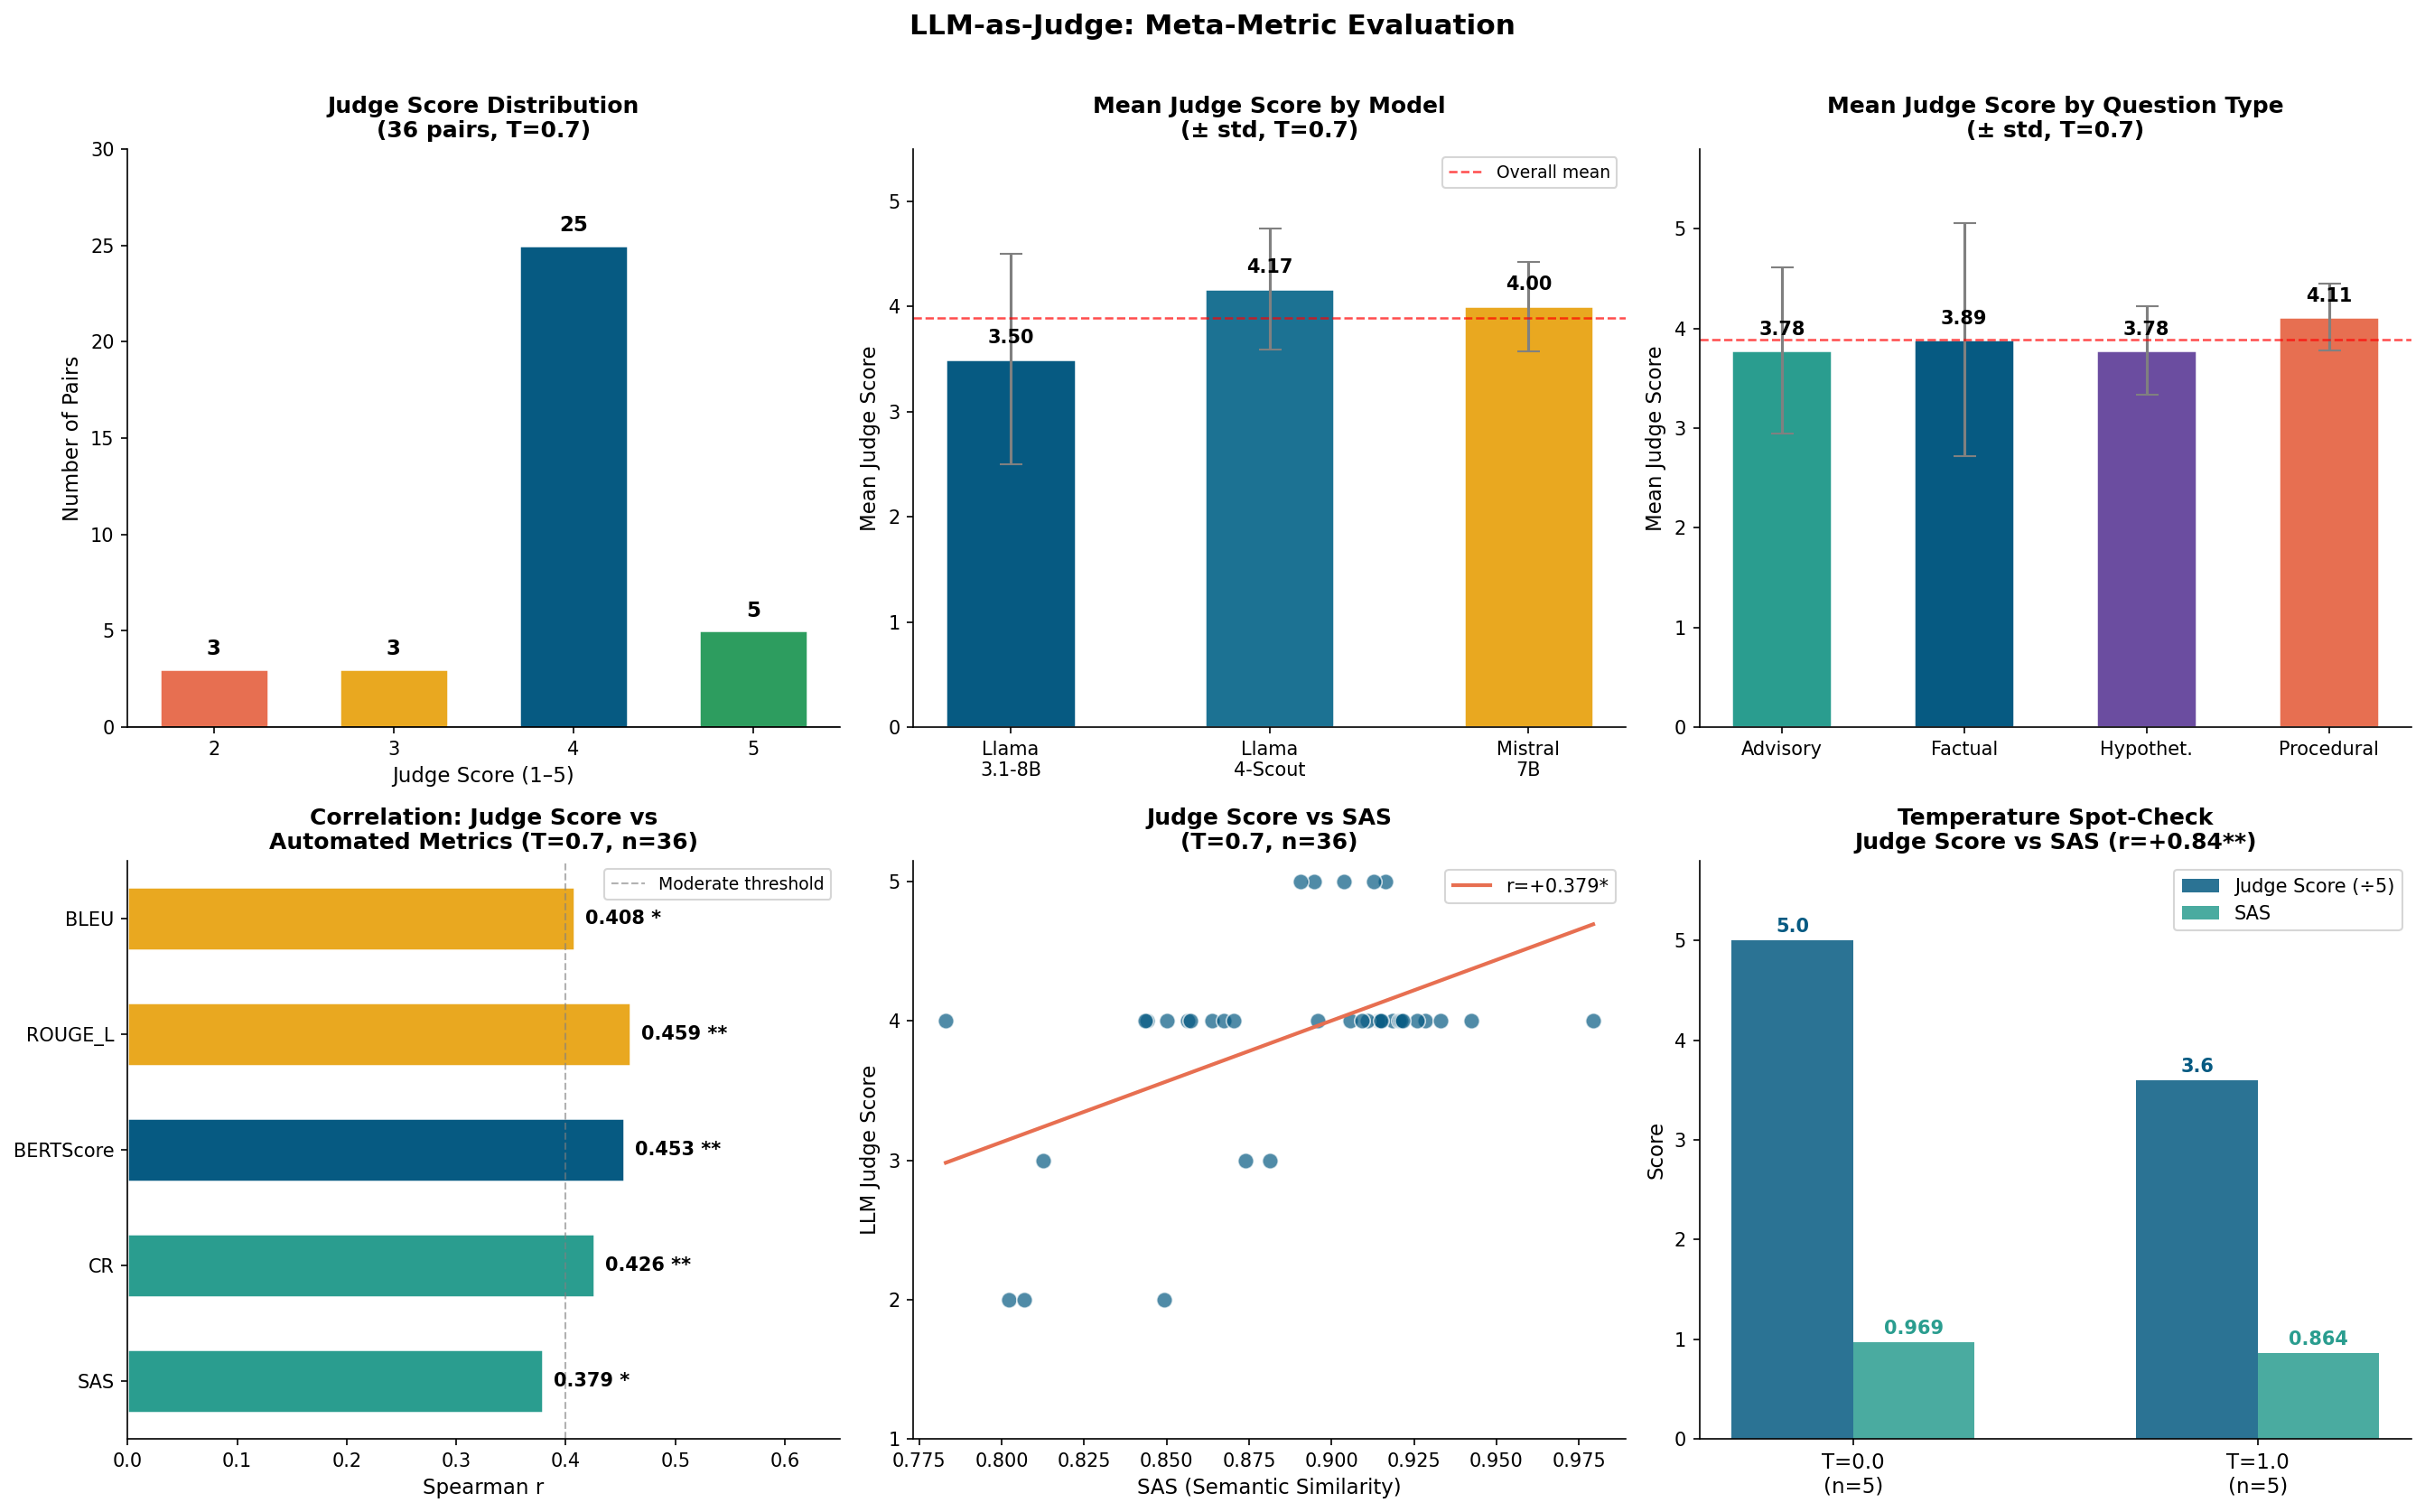

Saved → llm_judge_results.png


In [ ]:
# Cell 6 — All LLM-as-Judge Charts
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

CHART_PATH = "/content/drive/MyDrive/"
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 150})

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("LLM-as-Judge: Meta-Metric Evaluation", fontsize=15, fontweight="bold", y=1.01)

# ── 1. Score Distribution ──────────────────────────────────────────────────────
ax = axes[0, 0]
scores = [2, 3, 4, 5]
counts = [3, 3, 25, 5]
colors = ["#E76F51", "#E9A820", "#065A82", "#2D9D5F"]
bars = ax.bar(scores, counts, color=colors, edgecolor="white", linewidth=1.2, width=0.6)
ax.set_xlabel("Judge Score (1–5)", fontsize=11)
ax.set_ylabel("Number of Pairs", fontsize=11)
ax.set_title("Judge Score Distribution\n(36 pairs, T=0.7)", fontsize=12, fontweight="bold")
ax.set_xticks(scores)
ax.set_ylim(0, 30)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            str(count), ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.axhline(y=0, color="black", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)

# ── 2. Mean Judge Score by Model ──────────────────────────────────────────────
ax = axes[0, 1]
models      = ["llama-3.1-8b", "llama-4-scout", "mistral-7b"]
means_model = [3.500, 4.167, 4.000]
stds_model  = [1.000, 0.577, 0.426]
colors_m    = ["#065A82", "#1C7293", "#E9A820"]
bars = ax.bar(models, means_model, yerr=stds_model, capsize=6,
              color=colors_m, edgecolor="white", linewidth=1.2, width=0.5,
              error_kw={"elinewidth": 1.5, "ecolor": "gray"})
ax.set_ylim(0, 5.5)
ax.set_ylabel("Mean Judge Score", fontsize=11)
ax.set_title("Mean Judge Score by Model\n(± std, T=0.7)", fontsize=12, fontweight="bold")
ax.axhline(y=3.889, color="red", linestyle="--", linewidth=1.2, alpha=0.7, label="Overall mean")
ax.legend(fontsize=9)
for bar, val in zip(bars, means_model):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.12,
            f"{val:.2f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_xticklabels(["Llama\n3.1-8B", "Llama\n4-Scout", "Mistral\n7B"], fontsize=10)
ax.spines[["top", "right"]].set_visible(False)

# ── 3. Mean Judge Score by Question Type ──────────────────────────────────────
ax = axes[0, 2]
types      = ["ADVISORY", "FACTUAL", "HYPOTHETICAL", "PROCEDURAL"]
means_type = [3.778, 3.889, 3.778, 4.111]
stds_type  = [0.833, 1.167, 0.441, 0.333]
colors_t   = ["#2A9D8F", "#065A82", "#6B4DA0", "#E76F51"]
bars = ax.bar(types, means_type, yerr=stds_type, capsize=6,
              color=colors_t, edgecolor="white", linewidth=1.2, width=0.55,
              error_kw={"elinewidth": 1.5, "ecolor": "gray"})
ax.set_ylim(0, 5.8)
ax.set_ylabel("Mean Judge Score", fontsize=11)
ax.set_title("Mean Judge Score by Question Type\n(± std, T=0.7)", fontsize=12, fontweight="bold")
ax.axhline(y=3.889, color="red", linestyle="--", linewidth=1.2, alpha=0.7)
for bar, val in zip(bars, means_type):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.12,
            f"{val:.2f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_xticklabels(["Advisory", "Factual", "Hypothet.", "Procedural"], fontsize=10)
ax.spines[["top", "right"]].set_visible(False)

# ── 4. Spearman r Comparison (all 5 metrics) ──────────────────────────────────
ax = axes[1, 0]
metric_names = ["SAS", "CR", "BERTScore", "ROUGE_L", "BLEU"]
r_values     = [0.3787, 0.4263, 0.4534, 0.4591, 0.4079]
sig_labels   = ["*", "**", "**", "**", "*"]
colors_r     = ["#2A9D8F", "#2A9D8F", "#065A82", "#E9A820", "#E9A820"]
bars = ax.barh(metric_names, r_values, color=colors_r, edgecolor="white", linewidth=1.2, height=0.55)
ax.set_xlim(0, 0.65)
ax.set_xlabel("Spearman r", fontsize=11)
ax.set_title("Correlation: Judge Score vs\nAutomated Metrics (T=0.7, n=36)", fontsize=12, fontweight="bold")
ax.axvline(x=0.4, color="gray", linestyle="--", linewidth=1, alpha=0.6, label="Moderate threshold")
ax.legend(fontsize=9)
for bar, val, sig in zip(bars, r_values, sig_labels):
    ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
            f"{val:.3f} {sig}", va="center", fontsize=10, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)

# ── 5. Scatter: Judge Score vs SAS ────────────────────────────────────────────
ax = axes[1, 1]
# Use judge_df from Cell 3 (already in memory)
sub_scatter = judge_df.dropna(subset=["judge_score", "SAS"])
ax.scatter(sub_scatter["SAS"], sub_scatter["judge_score"],
           color="#065A82", alpha=0.7, s=70, edgecolors="white", linewidth=0.8)
# Regression line
m, b = np.polyfit(sub_scatter["SAS"], sub_scatter["judge_score"], 1)
x_line = np.linspace(sub_scatter["SAS"].min(), sub_scatter["SAS"].max(), 100)
ax.plot(x_line, m*x_line + b, color="#E76F51", linewidth=2, label=f"r=+0.379*")
ax.set_xlabel("SAS (Semantic Similarity)", fontsize=11)
ax.set_ylabel("LLM Judge Score", fontsize=11)
ax.set_title("Judge Score vs SAS\n(T=0.7, n=36)", fontsize=12, fontweight="bold")
ax.legend(fontsize=10)
ax.set_yticks([1, 2, 3, 4, 5])
ax.spines[["top", "right"]].set_visible(False)

# ── 6. Temperature Spot-Check ─────────────────────────────────────────────────
ax = axes[1, 2]
temps = ["T=0.0\n(n=5)", "T=1.0\n(n=5)"]
judge_means = [5.0, 3.6]
sas_means   = [0.969, 0.864]

x = np.arange(2)
w = 0.3
b1 = ax.bar(x - w/2, judge_means, width=w, color="#065A82", label="Judge Score (÷5)", alpha=0.85)
b2 = ax.bar(x + w/2, sas_means,   width=w, color="#2A9D8F", label="SAS", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(temps, fontsize=11)
ax.set_ylim(0, 5.8)
ax.set_ylabel("Score", fontsize=11)
ax.set_title("Temperature Spot-Check\nJudge Score vs SAS (r=+0.84**)", fontsize=12, fontweight="bold")
ax.legend(fontsize=10)
for bar, val in zip(b1, judge_means):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.08,
            f"{val:.1f}", ha="center", fontsize=10, fontweight="bold", color="#065A82")
for bar, val in zip(b2, sas_means):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.08,
            f"{val:.3f}", ha="center", fontsize=10, fontweight="bold", color="#2A9D8F")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(CHART_PATH + "llm_judge_results.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved → llm_judge_results.png")